# Football Team Performance Profiling — Clustering Analysis

## Objective

This notebook compares K-Means, Ward hierarchical clustering, and Gaussian Mixture Models using the 15 features selected during EDA. It selects the final model, interprets season-specific team archetypes, analyses profile transitions, and exports reproducible deployment artifacts.

## 1. Imports, Paths, and Data Loading

The saved feature list defines the deterministic input order used for scaling, modelling, and deployment.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "team_season_features_eda.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "team_profiling"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
FEATURE_PATH = TABLES_DIR / "final_clustering_features.csv"
MODEL_DIR = PROJECT_ROOT / "models" / "team_profiling"
for directory in (FIGURES_DIR, TABLES_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Input dataset not found: {DATA_PATH}"
assert FEATURE_PATH.is_file(), f"Feature list not found: {FEATURE_PATH}"

team_data = pd.read_csv(DATA_PATH)
final_features = pd.read_csv(FEATURE_PATH)["feature"].tolist()
X = team_data.loc[:, final_features].copy()

load_checks = pd.Series({
    "team_season_observations": len(team_data),
    "clustering_features": len(final_features),
    "missing_feature_values": int(X.isna().sum().sum()),
    "duplicate_features": len(final_features) - len(set(final_features)),
}, name="value")
display(load_checks.to_frame())
display(pd.DataFrame({"feature": final_features}))

assert X.columns.tolist() == final_features
assert len(final_features) == 15
assert load_checks["missing_feature_values"] == 0
assert load_checks["duplicate_features"] == 0

,value
team_season_observations,1028
clustering_features,15
missing_feature_values,0
duplicate_features,0


,feature
0,avg_overall_rating
1,development_gap
2,goalkeeper_relative_strength
3,avg_pace
4,avg_physical
5,avg_defence
6,attack_defence_balance
7,buildUpPlaySpeed
8,buildUpPlayPassing
9,chanceCreationPassing


## 2. Feature Scaling

`StandardScaler` gives each feature comparable influence in the distance-based methods. The same scaler fitted here is later saved for deployment.

In [2]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=final_features,
    index=X.index,
)

scaling_check = pd.DataFrame({
    "mean": X_scaled.mean(),
    "population_std": X_scaled.std(ddof=0),
}).round(6)
display(scaling_check)
assert np.allclose(X_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-10)

,mean,population_std
avg_overall_rating,0.0,1.0
development_gap,0.0,1.0
goalkeeper_relative_strength,0.0,1.0
avg_pace,-0.0,1.0
avg_physical,0.0,1.0
avg_defence,0.0,1.0
attack_defence_balance,-0.0,1.0
buildUpPlaySpeed,0.0,1.0
buildUpPlayPassing,-0.0,1.0
chanceCreationPassing,-0.0,1.0


## 3. K-Means Cluster-Count Selection

One evaluation loop compares `k=2` through `k=10` using inertia, Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score. Numerical separation and the practical usefulness of the resulting profile detail are considered together.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,13054.2593,0.1378,2.2418,185.9355
1,3,12109.6524,0.1044,2.4880,140.0992
2,4,11415.5186,0.1076,2.2450,119.7373
3,5,10846.2441,0.1003,2.1681,107.8473
4,6,10475.2498,0.0960,2.1371,96.4852
5,7,10184.5186,0.0884,2.2391,87.4763
6,8,9911.4109,0.0913,2.2613,80.9855
7,9,9684.3481,0.0854,2.3649,75.4391
8,10,9453.2475,0.0870,2.2644,71.3941


,k,cluster,count,percentage
9,5,0,231,22.47
10,5,1,206,20.04
11,5,2,162,15.76
12,5,3,289,28.11
13,5,4,140,13.62


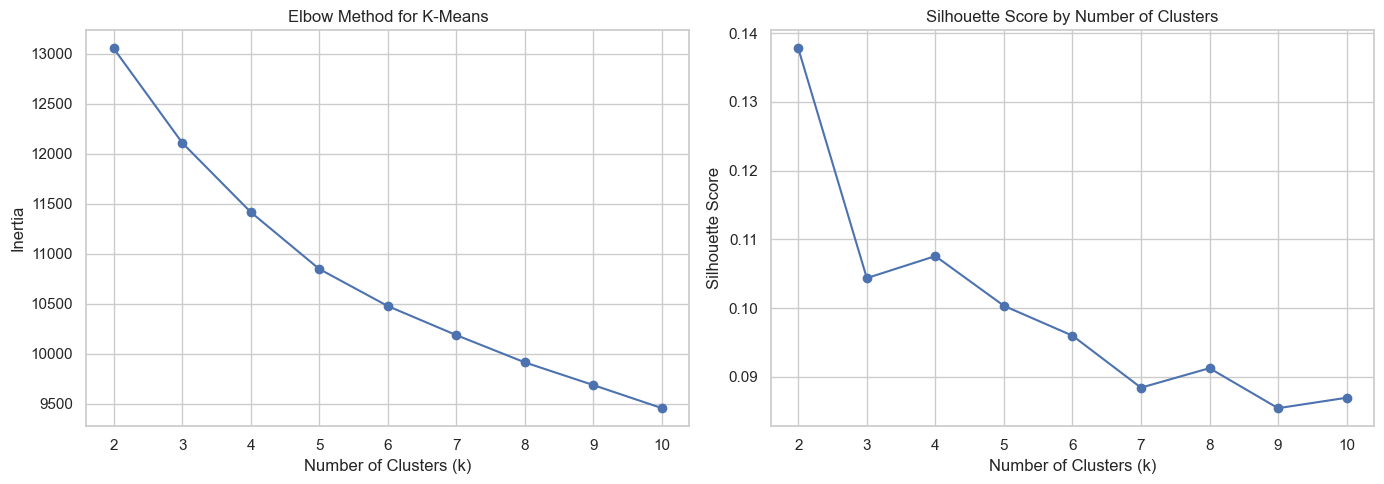

,silhouette,davies_bouldin,calinski_harabasz
K-Means (k=5),0.1003,2.1681,107.8473


In [3]:
kmeans_evaluations = []
kmeans_cluster_sizes = []

for k in range(2, 11):
    candidate_model = KMeans(n_clusters=k, random_state=42, n_init=20)
    candidate_labels = candidate_model.fit_predict(X_scaled)
    kmeans_evaluations.append({
        "k": k,
        "inertia": candidate_model.inertia_,
        "silhouette": silhouette_score(X_scaled, candidate_labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, candidate_labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, candidate_labels),
    })
    for cluster, count in pd.Series(candidate_labels).value_counts().sort_index().items():
        kmeans_cluster_sizes.append({
            "k": k,
            "cluster": cluster,
            "count": count,
            "percentage": count / len(X_scaled) * 100,
        })

kmeans_evaluation = pd.DataFrame(kmeans_evaluations)
kmeans_sizes = pd.DataFrame(kmeans_cluster_sizes)
display(kmeans_evaluation.round(4))
display(kmeans_sizes.query("k == 5").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(kmeans_evaluation["k"], kmeans_evaluation["inertia"], marker="o")
axes[0].set(title="Elbow Method for K-Means", xlabel="Number of Clusters (k)", ylabel="Inertia")
axes[1].plot(kmeans_evaluation["k"], kmeans_evaluation["silhouette"], marker="o")
axes[1].set(title="Silhouette Score by Number of Clusters", xlabel="Number of Clusters (k)", ylabel="Silhouette Score")
for axis in axes:
    axis.set_xticks(range(2, 11))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_selection_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

final_kmeans = KMeans(n_clusters=5, random_state=42, n_init=20)
kmeans_labels = final_kmeans.fit_predict(X_scaled)
team_data["kmeans_cluster"] = kmeans_labels
kmeans_metrics = {
    "silhouette": silhouette_score(X_scaled, kmeans_labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, kmeans_labels),
    "calinski_harabasz": calinski_harabasz_score(X_scaled, kmeans_labels),
}
display(pd.DataFrame([kmeans_metrics], index=["K-Means (k=5)"]).round(4))

### Decision

`k=2` gives the strongest broad numerical separation, but all absolute silhouette scores are low and indicate overlapping team characteristics. Four- and five-cluster solutions provide more useful profiling detail; `k=5` is retained because it has healthy cluster sizes and meaningful distinctions, with a Silhouette Score of about 0.1003 and Davies-Bouldin Index of about 2.1681.

## 4. Hierarchical Clustering

Ward hierarchical clustering is evaluated with five clusters for a like-for-like comparison with the selected K-Means solution.

In [4]:
hierarchical_model = AgglomerativeClustering(n_clusters=5, linkage="ward")
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)
hierarchical_metrics = {
    "silhouette": silhouette_score(X_scaled, hierarchical_labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, hierarchical_labels),
    "calinski_harabasz": calinski_harabasz_score(X_scaled, hierarchical_labels),
}
hierarchical_sizes = pd.Series(hierarchical_labels).value_counts().sort_index().rename("count").to_frame()
hierarchical_sizes["percentage"] = hierarchical_sizes["count"] / len(X_scaled) * 100

display(pd.DataFrame([hierarchical_metrics], index=["Hierarchical (k=5)"]).round(4))
display(hierarchical_sizes.round(2))

,silhouette,davies_bouldin,calinski_harabasz
Hierarchical (k=5),0.0686,2.6068,84.3548


,count,percentage
0,205,19.94
1,154,14.98
2,234,22.76
3,152,14.79
4,283,27.53


### Finding

Ward clustering has a lower Silhouette and Calinski-Harabasz score and a higher Davies-Bouldin value than K-Means. Its groups are therefore less compact and clearly separated for this dataset.

## 5. Gaussian Mixture Model

GMM configurations are compared across four covariance structures and 2–10 components. The lowest-BIC configuration is selected programmatically, then evaluated for separation, group balance, and posterior membership concentration (a GMM-specific diagnostic).

,covariance_type,components,AIC,BIC
23,tied,7,37190.99,38331.06
22,tied,6,37294.01,38355.11
25,tied,9,37113.64,38411.64
26,tied,10,37038.57,38415.53
24,tied,8,37213.82,38432.85
21,tied,5,37452.99,38435.12
20,tied,4,37574.56,38477.73
19,tied,3,37653.91,38478.11
18,tied,2,37753.35,38498.59
27,full,2,37229.02,38566.51


,silhouette,davies_bouldin,calinski_harabasz,AIC,BIC
"GMM (tied, 7 components)",0.0421,2.5545,46.0667,37190.9856,38331.0562


,count,percentage
0,594,57.78
1,87,8.46
2,49,4.77
3,72,7.00
4,119,11.58
5,28,2.72
6,79,7.68


Average maximum GMM posterior probability: 0.875


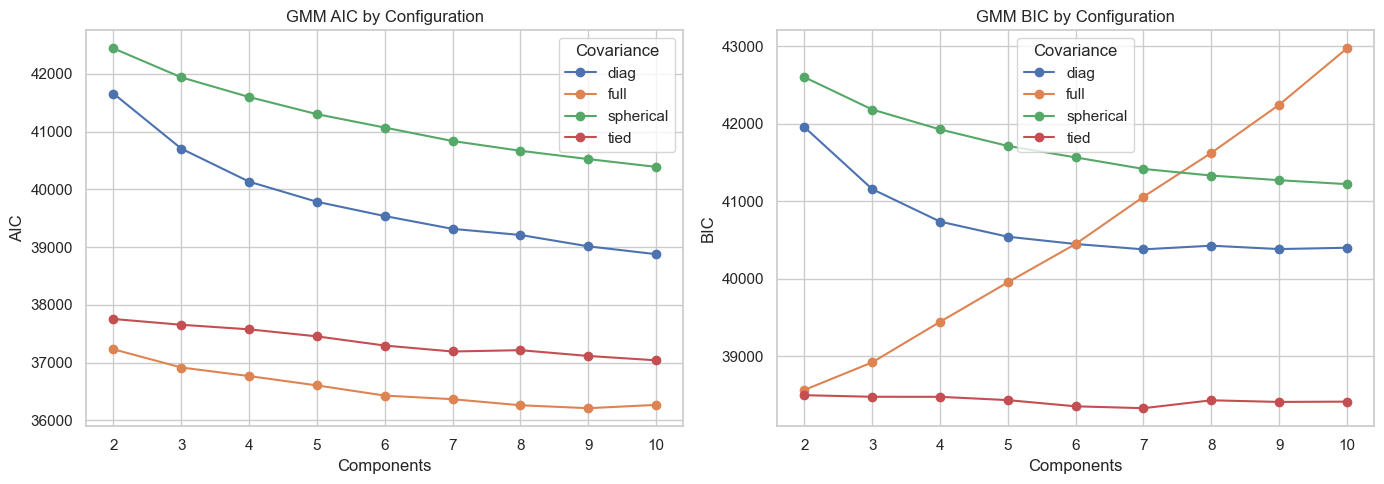

In [5]:
gmm_selection_rows = []
for covariance_type in ["spherical", "diag", "tied", "full"]:
    for n_components in range(2, 11):
        candidate_gmm = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            random_state=42,
            n_init=10,
        )
        candidate_gmm.fit(X_scaled)
        gmm_selection_rows.append({
            "covariance_type": covariance_type,
            "components": n_components,
            "AIC": candidate_gmm.aic(X_scaled),
            "BIC": candidate_gmm.bic(X_scaled),
        })

gmm_selection = pd.DataFrame(gmm_selection_rows)
best_gmm_config = gmm_selection.loc[gmm_selection["BIC"].idxmin()]
best_gmm = GaussianMixture(
    n_components=int(best_gmm_config["components"]),
    covariance_type=best_gmm_config["covariance_type"],
    random_state=42,
    n_init=10,
)
best_gmm_labels = best_gmm.fit_predict(X_scaled)
best_gmm_probabilities = best_gmm.predict_proba(X_scaled)
best_gmm_confidence = best_gmm_probabilities.max(axis=1)
gmm_metrics = {
    "silhouette": silhouette_score(X_scaled, best_gmm_labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, best_gmm_labels),
    "calinski_harabasz": calinski_harabasz_score(X_scaled, best_gmm_labels),
    "AIC": best_gmm.aic(X_scaled),
    "BIC": best_gmm.bic(X_scaled),
}
gmm_sizes = pd.Series(best_gmm_labels).value_counts().sort_index().rename("count").to_frame()
gmm_sizes["percentage"] = gmm_sizes["count"] / len(X_scaled) * 100

display(gmm_selection.sort_values("BIC").head(15).round(2))
display(pd.DataFrame([gmm_metrics], index=[
    f"GMM ({best_gmm.covariance_type}, {best_gmm.n_components} components)"
]).round(4))
display(gmm_sizes.round(2))
print("Average maximum GMM posterior probability:", round(best_gmm_confidence.mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for covariance_type, values in gmm_selection.groupby("covariance_type"):
    axes[0].plot(values["components"], values["AIC"], marker="o", label=covariance_type)
    axes[1].plot(values["components"], values["BIC"], marker="o", label=covariance_type)
axes[0].set(title="GMM AIC by Configuration", xlabel="Components", ylabel="AIC")
axes[1].set(title="GMM BIC by Configuration", xlabel="Components", ylabel="BIC")
for axis in axes:
    axis.set_xticks(range(2, 11))
    axis.legend(title="Covariance")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gmm_model_selection.png", dpi=300, bbox_inches="tight")
plt.show()

assert best_gmm.covariance_type == "tied"
assert best_gmm.n_components == 7

### Finding

BIC selects a tied-covariance, seven-component GMM. Its separation is weaker than K-Means (Silhouette about 0.0421, Davies-Bouldin about 2.5545, and Calinski-Harabasz about 46.07), and its largest group contains about 57.78% of observations. The probabilistic model therefore produces a strongly imbalanced structure despite its model-based fit.

## 6. Final Model Comparison and Selection

The comparison table is built directly from the fitted-model metrics rather than manually entered values.

In [6]:
model_comparison = pd.DataFrame([
    {"model": "K-Means (k=5)", **kmeans_metrics},
    {"model": "Hierarchical (k=5)", **hierarchical_metrics},
    {
        "model": f"GMM ({best_gmm.covariance_type}, {best_gmm.n_components} components)",
        **{metric: gmm_metrics[metric] for metric in (
            "silhouette", "davies_bouldin", "calinski_harabasz"
        )},
    },
])
display(model_comparison.round(4))

,model,silhouette,davies_bouldin,calinski_harabasz
0,K-Means (k=5),0.1003,2.1681,107.8473
1,Hierarchical (k=5),0.0686,2.6068,84.3548
2,"GMM (tied, 7 components)",0.0421,2.5545,46.0667


### Decision

K-Means with five clusters is selected because it has the strongest separation metrics of the three final candidates, healthier group sizes than the BIC-selected GMM, and useful profile distinctions. The low absolute silhouette remains an important limitation: the clusters are overlapping archetypes, not sharply separated natural categories.

## 7. Final Team-Profile Interpretation

Representative team-seasons are the five observations nearest each K-Means centroid. Historical performance variables were not used to form the clusters; they are added only now to interpret the profiles.

,avg_overall_rating,development_gap,goalkeeper_relative_strength,avg_pace,avg_physical,avg_defence,attack_defence_balance,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth
cluster,,,,,,,,,,,,,,,
0,0.44,-0.48,0.14,-0.01,0.58,0.72,-0.55,0.47,0.58,0.06,0.09,-0.35,-0.65,-0.10,-0.44
1,-0.25,0.42,0.12,-0.04,-0.21,-0.35,0.10,0.26,0.18,0.35,0.43,0.24,0.68,0.54,0.82
2,0.58,0.17,0.15,0.56,0.27,0.28,0.55,-1.05,-1.04,-0.79,-0.37,-0.27,-0.00,-0.36,-0.04
3,-1.14,0.10,-0.21,-0.91,-1.07,-1.02,-0.20,-0.13,0.10,-0.24,-0.31,-0.17,-0.34,-0.39,-0.28
4,1.33,-0.23,-0.14,1.32,1.26,1.11,0.53,0.34,-0.21,0.78,0.28,0.87,0.76,0.58,0.14


,cluster,feature,centroid_value,team_profile
0,0,avg_defence,0.72,Physical Defensive Build-Up
1,0,defencePressure,-0.65,Physical Defensive Build-Up
2,0,buildUpPlayPassing,0.58,Physical Defensive Build-Up
3,0,avg_physical,0.58,Physical Defensive Build-Up
4,0,attack_defence_balance,-0.55,Physical Defensive Build-Up
5,1,defenceTeamWidth,0.82,High-Pressure Wide Play
6,1,defencePressure,0.68,High-Pressure Wide Play
7,1,defenceAggression,0.54,High-Pressure Wide Play
8,1,chanceCreationCrossing,0.43,High-Pressure Wide Play
9,1,development_gap,0.42,High-Pressure Wide Play


,cluster,team_profile,team_name,season,league_name,points_per_match,distance_to_centroid
0,0,Physical Defensive Build-Up,Wolverhampton Wanderers,2011/2012,England Premier League,0.676,1.446
1,0,Physical Defensive Build-Up,FC Ingolstadt 04,2015/2016,Germany 1. Bundesliga,1.034,1.606
2,0,Physical Defensive Build-Up,Queens Park Rangers,2011/2012,England Premier League,0.909,1.789
3,0,Physical Defensive Build-Up,Queens Park Rangers,2014/2015,England Premier League,0.789,1.803
4,0,Physical Defensive Build-Up,Queens Park Rangers,2012/2013,England Premier League,0.658,1.832
5,1,High-Pressure Wide Play,Celtic,2015/2016,Scotland Premier League,2.263,1.480
6,1,High-Pressure Wide Play,FC Groningen,2015/2016,Netherlands Eredivisie,1.471,1.490
7,1,High-Pressure Wide Play,FC Augsburg,2012/2013,Germany 1. Bundesliga,1.000,1.702
8,1,High-Pressure Wide Play,AZ,2014/2015,Netherlands Eredivisie,1.750,1.707
9,1,High-Pressure Wide Play,Real Sociedad,2015/2016,Spain LIGA BBVA,1.263,1.726


,,team_seasons,points_per_match,goals_for_per_match,goals_against_per_match,goal_difference_per_match,win_rate
kmeans_cluster,team_profile,,,,,,
0,Physical Defensive Build-Up,231,1.247,1.223,1.415,-0.192,0.327
1,High-Pressure Wide Play,206,1.368,1.368,1.378,-0.010,0.372
2,Strong Attack-Oriented Controlled Build-Up,162,1.522,1.532,1.290,0.242,0.424
3,Lower-Strength Profile,289,1.153,1.195,1.543,-0.348,0.297
4,Elite All-Round Profile,140,1.860,1.805,1.056,0.749,0.545


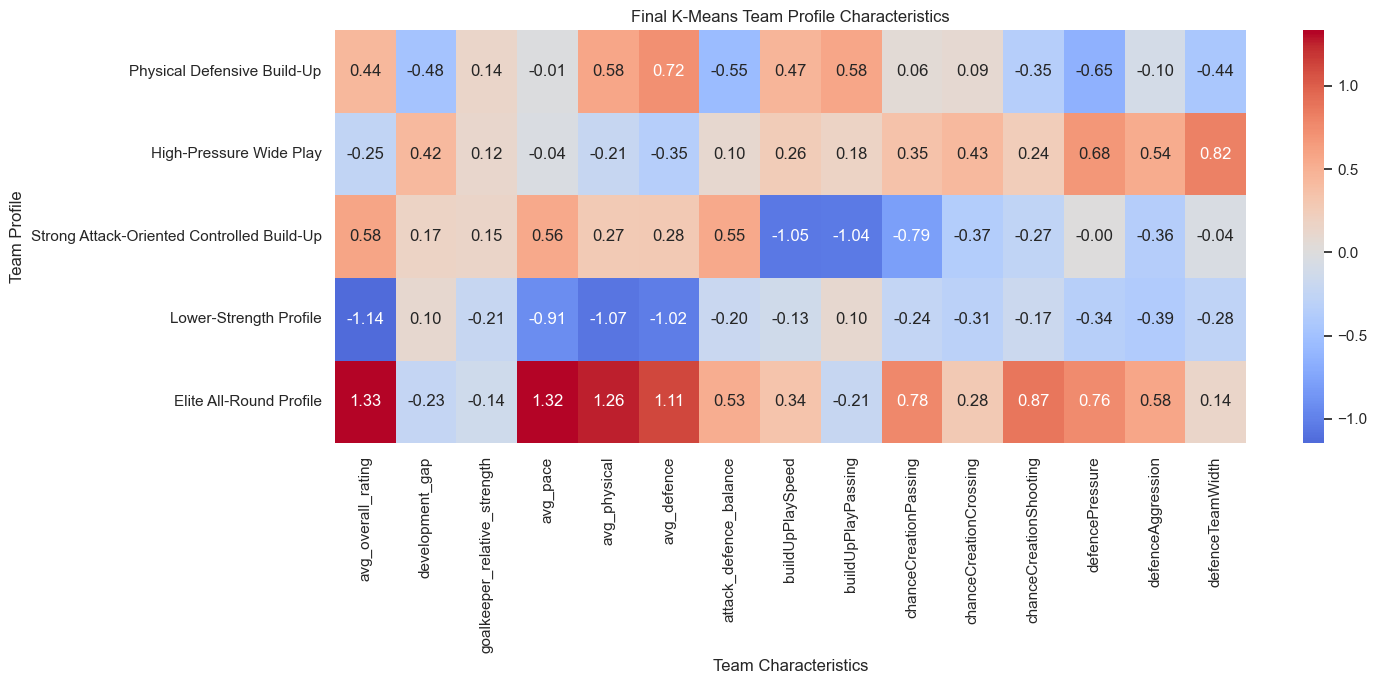

In [7]:
profile_names = {
    0: "Physical Defensive Build-Up",
    1: "High-Pressure Wide Play",
    2: "Strong Attack-Oriented Controlled Build-Up",
    3: "Lower-Strength Profile",
    4: "Elite All-Round Profile",
}
team_data["team_profile"] = team_data["kmeans_cluster"].map(profile_names)

final_centroids = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=final_features,
    index=pd.Index(range(5), name="cluster"),
)
profile_defining_features = (
    final_centroids
    .apply(lambda row: row.abs().nlargest(5).index.tolist(), axis=1)
    .explode()
    .rename("feature")
    .reset_index()
)
profile_defining_features["centroid_value"] = [
    final_centroids.loc[row.cluster, row.feature]
    for row in profile_defining_features.itertuples()
]
profile_defining_features["team_profile"] = profile_defining_features["cluster"].map(profile_names)

representative_rows = []
for cluster in range(5):
    cluster_index = X_scaled.index[kmeans_labels == cluster]
    cluster_points = X_scaled.loc[cluster_index]
    distances = np.linalg.norm(
        cluster_points.to_numpy() - final_kmeans.cluster_centers_[cluster], axis=1
    )
    nearest = pd.Series(distances, index=cluster_index).nsmallest(5)
    examples = team_data.loc[nearest.index, [
        "season", "league_name", "team_api_id", "team_name",
        "points_per_match", "win_rate",
    ]].copy()
    examples["cluster"] = cluster
    examples["team_profile"] = profile_names[cluster]
    examples["distance_to_centroid"] = nearest.to_numpy()
    representative_rows.append(examples)
representative_teams = pd.concat(representative_rows, ignore_index=True)

profile_summary = (
    team_data.groupby(["kmeans_cluster", "team_profile"])
    .agg(
        team_seasons=("team_api_id", "count"),
        points_per_match=("points_per_match", "mean"),
        goals_for_per_match=("goals_for_per_match", "mean"),
        goals_against_per_match=("goals_against_per_match", "mean"),
        goal_difference_per_match=("goal_difference_per_match", "mean"),
        win_rate=("win_rate", "mean"),
    )
    .round(3)
    .sort_index()
)

display(final_centroids.round(2))
display(profile_defining_features.round(2))
display(representative_teams[[
    "cluster", "team_profile", "team_name", "season", "league_name",
    "points_per_match", "distance_to_centroid",
]].round(3))
display(profile_summary)

centroid_plot = final_centroids.copy()
centroid_plot.index = [profile_names[cluster] for cluster in centroid_plot.index]
plt.figure(figsize=(15, 7))
sns.heatmap(centroid_plot, annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Final K-Means Team Profile Characteristics")
plt.xlabel("Team Characteristics")
plt.ylabel("Team Profile")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_kmeans_profile_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding

The five profiles retain their established names and historical interpretation. Average points per match is approximately 1.247 for Physical Defensive Build-Up, 1.368 for High-Pressure Wide Play, 1.522 for Strong Attack-Oriented Controlled Build-Up, 1.153 for Lower-Strength Profile, and 1.860 for Elite All-Round Profile. The Elite profile also has an average win rate of about 0.545.

## 8. Club Profile Transitions

Consecutive observed seasons are compared within each club. This tests whether a profile behaves as a permanent club label or as a season-specific archetype.

In [8]:
season_order = {season: index for index, season in enumerate(sorted(team_data["season"].unique()))}
transition_data = team_data[[
    "team_api_id", "team_name", "season", "team_profile",
    "kmeans_cluster", "points_per_match",
]].copy()
transition_data["season_order"] = transition_data["season"].map(season_order)
transition_data = transition_data.sort_values(["team_api_id", "season_order"])
transition_data["previous_profile"] = transition_data.groupby("team_api_id")["team_profile"].shift()
transition_data["previous_cluster"] = transition_data.groupby("team_api_id")["kmeans_cluster"].shift()
transition_data["previous_season_order"] = transition_data.groupby("team_api_id")["season_order"].shift()
transition_data["consecutive"] = (
    transition_data["season_order"] - transition_data["previous_season_order"] == 1
)
transitions = transition_data.loc[
    transition_data["previous_profile"].notna() & transition_data["consecutive"]
].copy()
transitions["profile_changed"] = transitions["team_profile"] != transitions["previous_profile"]

transition_summary = pd.DataFrame({
    "transitions": [len(transitions)],
    "profile_changes": [int(transitions["profile_changed"].sum())],
    "profile_stays": [int((~transitions["profile_changed"]).sum())],
    "change_percentage": [transitions["profile_changed"].mean() * 100],
})
common_profile_changes = (
    transitions.loc[transitions["profile_changed"]]
    .groupby(["previous_profile", "team_profile"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
display(transition_summary.round(2))
display(common_profile_changes.head(10))

assert transition_summary.loc[0, "transitions"] == 724
assert transition_summary.loc[0, "profile_changes"] == 205
assert transition_summary.loc[0, "profile_stays"] == 519

,transitions,profile_changes,profile_stays,change_percentage
0,724,205,519,28.31


,previous_profile,team_profile,count
5,High-Pressure Wide Play,Physical Defensive Build-Up,25
4,High-Pressure Wide Play,Lower-Strength Profile,17
17,Strong Attack-Oriented Controlled Build-Up,Physical Defensive Build-Up,16
2,Elite All-Round Profile,Strong Attack-Oriented Controlled Build-Up,16
16,Strong Attack-Oriented Controlled Build-Up,Lower-Strength Profile,15
6,High-Pressure Wide Play,Strong Attack-Oriented Controlled Build-Up,15
15,Strong Attack-Oriented Controlled Build-Up,High-Pressure Wide Play,15
1,Elite All-Round Profile,Physical Defensive Build-Up,14
7,Lower-Strength Profile,High-Pressure Wide Play,13
14,Strong Attack-Oriented Controlled Build-Up,Elite All-Round Profile,10


### Finding

Of 724 consecutive-season transitions, 205 change profile and 519 remain in the same profile, a 28.31% change rate. Profiles therefore have some stability but should be interpreted as season-specific archetypes rather than permanent club labels.

## 9. Business Findings and Recommendations

The Elite All-Round profile has the strongest historical outcomes, while the Strong Attack-Oriented Controlled Build-Up profile also performs above average. Physical and defensive strength alone does not guarantee strong results, and High-Pressure Wide Play is differentiated more by tactical intensity and width than by exceptional overall squad quality.

These profiles can support benchmarking, recruitment-gap analysis, and monitoring of strategic change between seasons. They are decision-support tools: associations between a profile and historical performance are not evidence that adopting that profile causes better results.

## 10. Limitations

- The final Silhouette Score is only about 0.10, so the archetypes overlap substantially.
- Historical seasons may not fully represent modern football tactics or player characteristics.
- Season-level aggregation hides match-to-match variation and within-season change.
- Feature selection, scaling, and the chosen cluster count influence the resulting structure.
- Combining European leagues may reflect differences in league strength, style, and competition format.
- Performance is examined after clustering; observed associations are not causal.

## 11. Export Final Models and Outputs

Only the selected K-Means labels are added to the exported team dataset. Temporary hierarchical and GMM labels are kept out of the deployment output.

In [9]:
assert X.columns.tolist() == final_features
assert scaler.n_features_in_ == len(final_features)
assert final_kmeans.n_features_in_ == len(final_features)
assert final_kmeans.n_clusters == 5
assert team_data["team_profile"].notna().all()

model_comparison.to_csv(TABLES_DIR / "clustering_model_comparison.csv", index=False)
team_data.to_csv(TABLES_DIR / "team_profiles_final.csv", index=False)
profile_summary.to_csv(TABLES_DIR / "team_profile_performance_summary.csv")
representative_teams.to_csv(TABLES_DIR / "representative_teams_by_profile.csv", index=False)
profile_defining_features.to_csv(TABLES_DIR / "profile_defining_features.csv", index=False)

final_centroids_export = final_centroids.copy()
final_centroids_export.index = [profile_names[cluster] for cluster in final_centroids_export.index]
final_centroids_export.index.name = "team_profile"
final_centroids_export.to_csv(TABLES_DIR / "final_profile_centroids.csv")
transitions.to_csv(TABLES_DIR / "club_profile_transitions.csv", index=False)
common_profile_changes.to_csv(TABLES_DIR / "common_profile_changes.csv", index=False)

joblib.dump(final_kmeans, MODEL_DIR / "team_profile_kmeans.joblib")
joblib.dump(scaler, MODEL_DIR / "team_profile_scaler.joblib")
with (MODEL_DIR / "final_features.json").open("w", encoding="utf-8") as file:
    json.dump(final_features, file, indent=4)
with (MODEL_DIR / "profile_names.json").open("w", encoding="utf-8") as file:
    json.dump({str(key): value for key, value in profile_names.items()}, file, indent=4)

with (MODEL_DIR / "final_features.json").open(encoding="utf-8") as file:
    assert json.load(file) == X.columns.tolist()

output_checks = pd.Series({
    "final_team_rows": len(team_data),
    "team_profiles": team_data["team_profile"].nunique(),
    "missing_profile_labels": int(team_data["team_profile"].isna().sum()),
    "model_files": len(list(MODEL_DIR.glob("*"))),
}, name="value")
display(output_checks.to_frame())

,value
final_team_rows,1028
team_profiles,5
missing_profile_labels,0
model_files,4


## 12. Conclusion

K-Means with five clusters remains the selected profiling method for 1,028 team-season observations and 15 ordered squad and tactical features. It outperforms the final Ward and BIC-selected GMM alternatives on the comparison metrics and produces five useful, though overlapping, team archetypes.

Performance differences and a 28.31% season-to-season profile change rate add practical context without changing how the clusters were formed. The saved scaler, model, feature order, profile-name mapping, labelled dataset, interpretation tables, and transition outputs provide a reproducible hand-off for later application use.